In [ ]:
from anemone.forwards import Forward, BaseForward
from anemone.experiment import *

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
tgates = np.array([[1.239e-05,  1.158e-05,  1.320e-05],
                   [1.439e-05,  1.358e-05,  1.520e-05],
                   [1.639e-05,  1.558e-05,  1.720e-05],
                   [1.839e-05,  1.758e-05,  1.920e-05],
                   [2.039e-05,  1.958e-05,  2.120e-05],
                   [2.289e-05,  2.158e-05,  2.420e-05],
                   [2.589e-05,  2.458e-05,  2.720e-05],
                   [2.939e-05,  2.758e-05,  3.120e-05],
                   [3.389e-05,  3.158e-05,  3.620e-05],
                   [3.989e-05,  3.658e-05,  4.320e-05],
                   [4.739e-05,  4.358e-05,  5.120e-05],
                   [5.639e-05,  5.158e-05,  6.120e-05],
                   [6.789e-05,  6.158e-05,  7.420e-05],
                   [8.239e-05,  7.458e-05,  9.020e-05],
                   [1.009e-04,  9.058e-05,  1.112e-04],
                   [1.244e-04,  1.116e-04,  1.372e-04],
                   [1.534e-04,  1.376e-04,  1.692e-04],
                   [1.904e-04,  1.696e-04,  2.112e-04],
                   [2.369e-04,  2.116e-04,  2.622e-04],
                   [2.949e-04,  2.626e-04,  3.272e-04],
                   [3.684e-04,  3.276e-04,  4.092e-04],
                   [4.609e-04,  4.096e-04,  5.122e-04],
                   [5.774e-04,  5.126e-04,  6.422e-04],
                   [7.239e-04,  6.426e-04,  8.052e-04],
                   [9.084e-04,  8.056e-04,  1.011e-03]]).T

tst = torch.from_numpy(tgates[1])
tfn = torch.from_numpy(tgates[2])
tc  = torch.from_numpy(tgates[0])

lp = Loop.square(40)
rx = Receiver()

t = np.array([-1.0526e-03, -9.2963e-04,  0.0000e+00,  2.5000e-06])
wv = np.array([0, 1, 1, 0])

waveform1 = Waveform(t, wv)

recfilter = FilterChain([
    ButterworthFilter(2.4e5, 1),
    ButterworthFilter(6.2e5, 1),
    ButterworthFilter(4.5e5, 2)
])

In [ ]:
fwr1 = Forward(lp, rx, tc, waveform1, recfilter, tfn-tst, tolerance=1e-5)
fwr0 = BaseForward(lp, rx, tc, waveform1, recfilter, tfn-tst)

c:\users\au646858\onedrive - aarhus universitet\documents\_repositories\anemone\src\anemone\experiment\experiment.py:129: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(overall_min)


In [5]:
rho = torch.ones(3)*40
thk = torch.ones(2)*20

dbdt0 = fwr0(rho, thk)
dbdt1 = fwr1(rho, thk)

c:\users\au646858\onedrive - aarhus universitet\documents\_repositories\anemone\src\anemone\experiment\experiment.py:274: UserWarning: The use of `x.T` on tensors of dimension other than 2 to reverse their shape is deprecated and it will throw an error in a future release. Consider `x.mT` to transpose batches of matrices or `x.permute(*torch.arange(x.ndim - 1, -1, -1))` to reverse the dimensions of a tensor. (Triggered internally at C:\cb\pytorch_1000000000000\work\aten\src\ATen\native\TensorShape.cpp:3618.)
  return HR.T.squeeze()


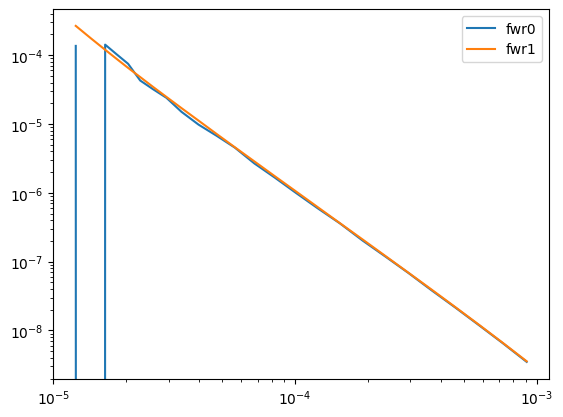

In [8]:
plt.figure()
plt.loglog(fwr0.times, dbdt0.detach().numpy(), label='fwr0')
plt.loglog(fwr1.times, dbdt1.detach().numpy(), label='fwr1')
plt.legend()